In [10]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display

# Set visualisation style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Create a folder for project outputs
os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [11]:
# Load the retail sales dataset

file_path = "/content/retail_sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24/11/2023,CUST001,Male,34,Beauty,3,50,150
1,2,27/02/2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13/01/2023,CUST003,Male,50,Electronics,1,30,30
3,4,21/05/2023,CUST004,Male,37,Clothing,1,500,500
4,5,06/05/2023,CUST005,Male,30,Beauty,2,50,100


In [12]:
# Dataset dimensions
print("Number of rows and columns:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Dataset information
print("\nDataset information:")
df.info()

Number of rows and columns: (1000, 9)

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   o

In [13]:
# Make a working copy
df = df.copy()

# Standardise column names
df.columns = df.columns.str.strip()

# Convert dates to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert numeric columns
numeric_columns = [
    "Age", "Quantity", "Price per Unit", "Total Amount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove duplicate records
df = df.drop_duplicates()

# Remove records with invalid dates or missing essential sales information
df = df.dropna(
    subset=["Date", "Quantity", "Price per Unit", "Total Amount"]
)

# Keep only valid positive sales values
df = df[
    (df["Quantity"] > 0) &
    (df["Price per Unit"] > 0) &
    (df["Total Amount"] >= 0)
]

# Create age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["Under 18", "18-30", "31-45", "46-60", "Above 60"]
)

# Create time analysis columns
df["Month"] = df["Date"].dt.to_period("M").astype(str)
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)

print("Cleaning completed.")
print("Remaining rows:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

display(df.head())

Cleaning completed.
Remaining rows: 1000
Remaining duplicates: 0


/tmp/ipykernel_851/1671993993.py:8: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Age Group,Month,Quarter
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,31-45,2023-11,2023Q4
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,18-30,2023-02,2023Q1
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,46-60,2023-01,2023Q1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,31-45,2023-05,2023Q2
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,18-30,2023-05,2023Q2


In [14]:
# Select numerical columns
numeric_data = df.select_dtypes(include=np.number)

# Calculate descriptive statistics
statistics = pd.DataFrame({
    "Mean": numeric_data.mean(),
    "Median": numeric_data.median(),
    "Mode": numeric_data.mode().iloc[0],
    "Standard Deviation": numeric_data.std()
})

display(statistics.round(2))

statistics.to_csv("outputs/descriptive_statistics.csv")

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


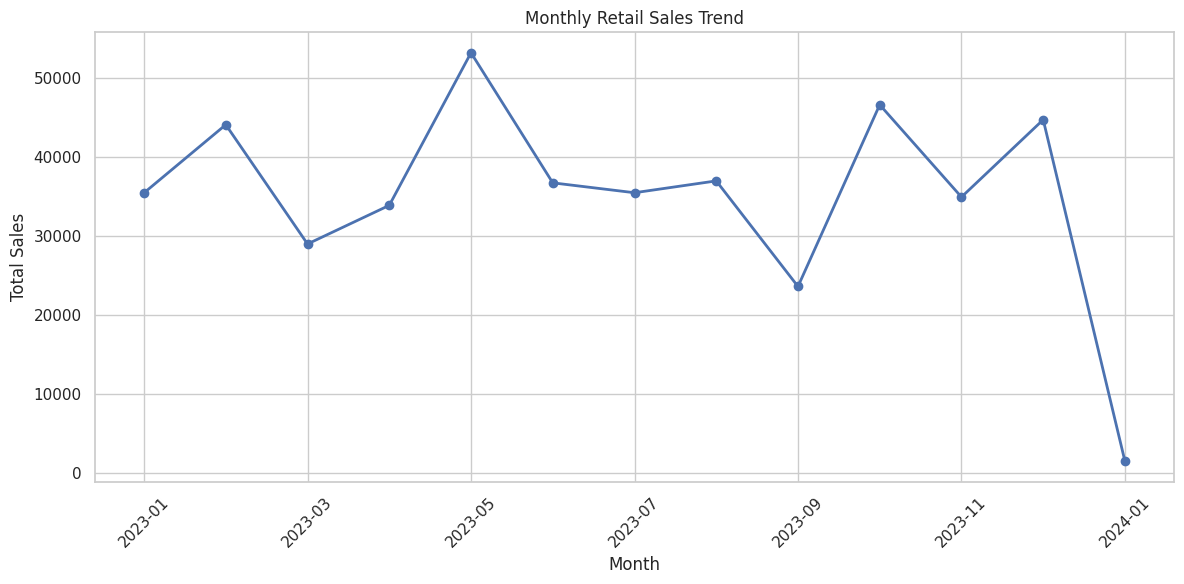

Highest sales month: 2023-05
Highest monthly sales: 53150
Lowest sales month: 2024-01
Lowest monthly sales: 1530


In [15]:
# Calculate monthly sales
monthly_sales = (
    df.groupby("Month")["Total Amount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 6))

monthly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("outputs/monthly_sales_trend.png", dpi=300)
plt.show()

print("Highest sales month:", monthly_sales.idxmax())
print("Highest monthly sales:", monthly_sales.max())
print("Lowest sales month:", monthly_sales.idxmin())
print("Lowest monthly sales:", monthly_sales.min())

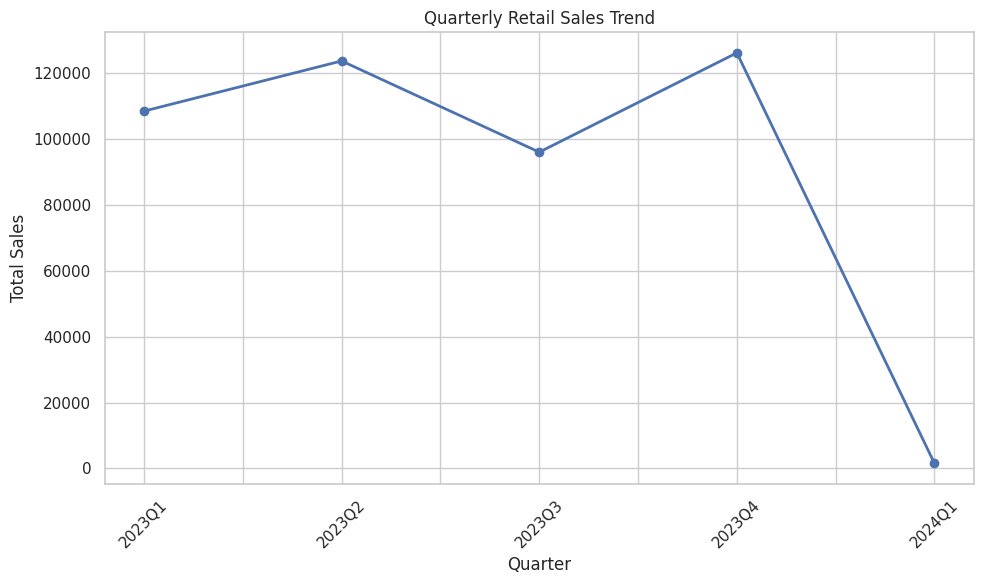

,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


In [16]:
# Calculate quarterly sales
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 6))

quarterly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("outputs/quarterly_sales_trend.png", dpi=300)
plt.show()

display(quarterly_sales)

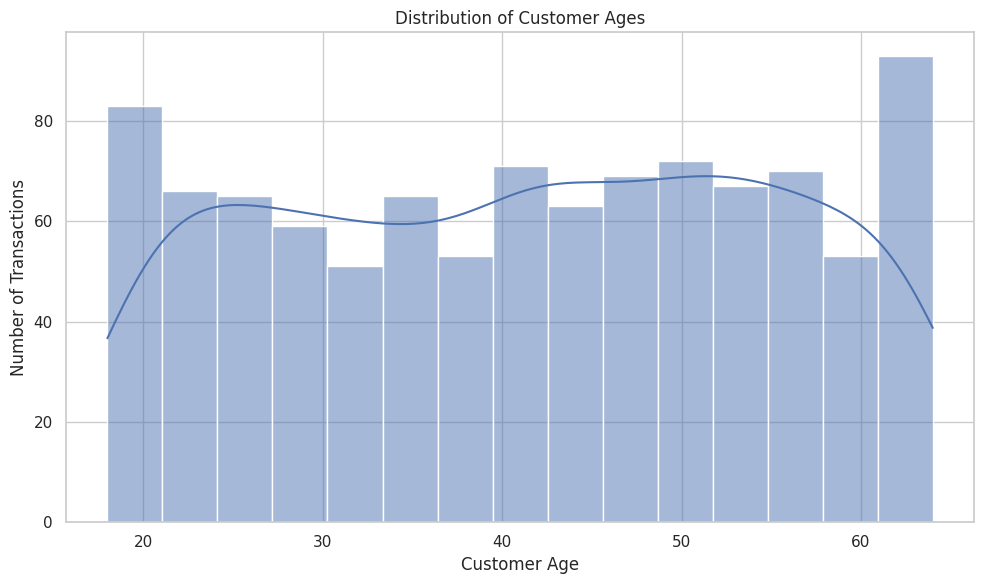

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Ages")
plt.xlabel("Customer Age")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.savefig("outputs/customer_age_distribution.png", dpi=300)
plt.show()

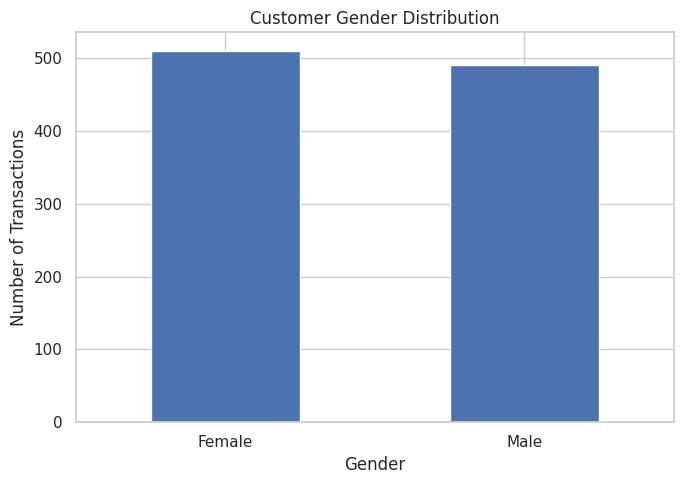

,count
Gender,
Female,510
Male,490


In [18]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 5))

gender_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.savefig("outputs/gender_distribution.png", dpi=300)
plt.show()

display(gender_counts)

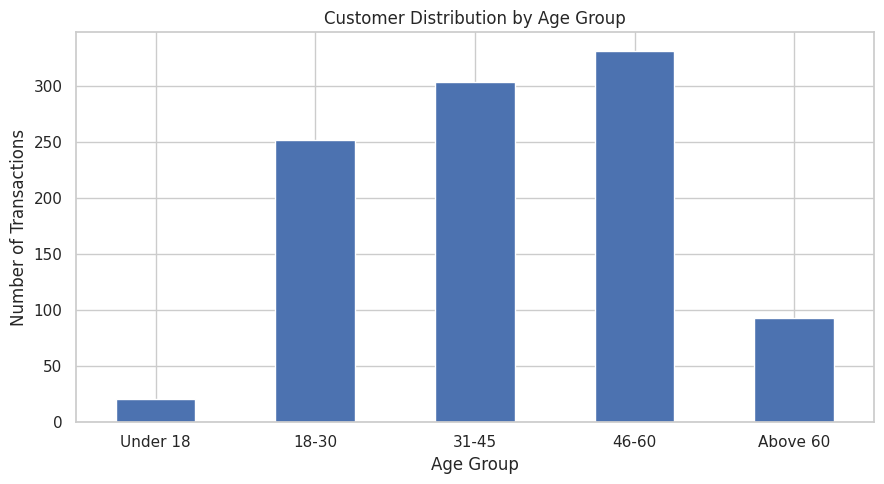

,count
Age Group,
Under 18,21
18-30,252
31-45,303
46-60,331
Above 60,93


In [19]:
age_group_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

age_group_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.savefig("outputs/age_group_distribution.png", dpi=300)
plt.show()

display(age_group_counts)

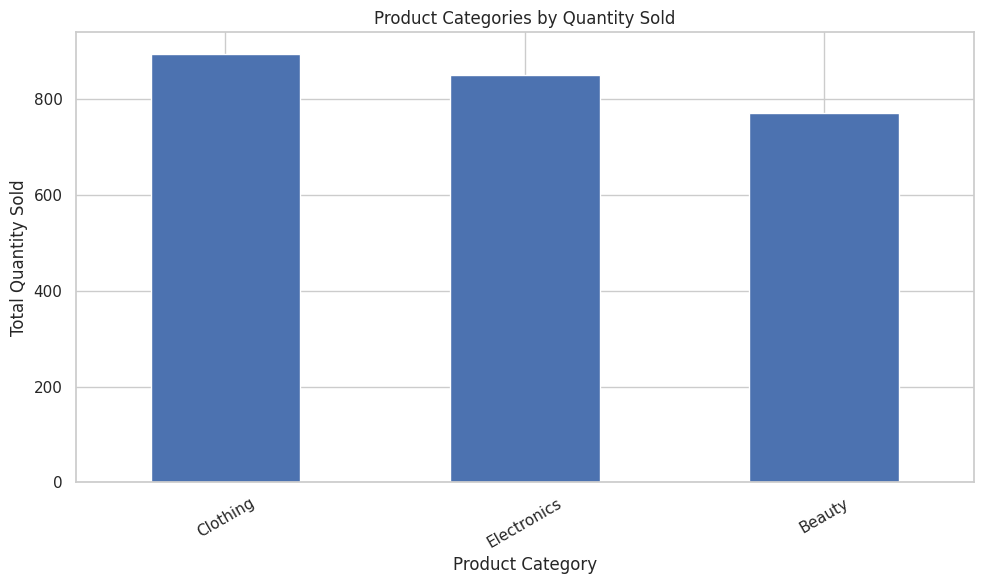

,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


In [20]:
category_quantity = (
    df.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

category_quantity.plot(
    kind="bar",
    rot=30
)

plt.title("Product Categories by Quantity Sold")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.tight_layout()

plt.savefig("outputs/category_quantity.png", dpi=300)
plt.show()

display(category_quantity)

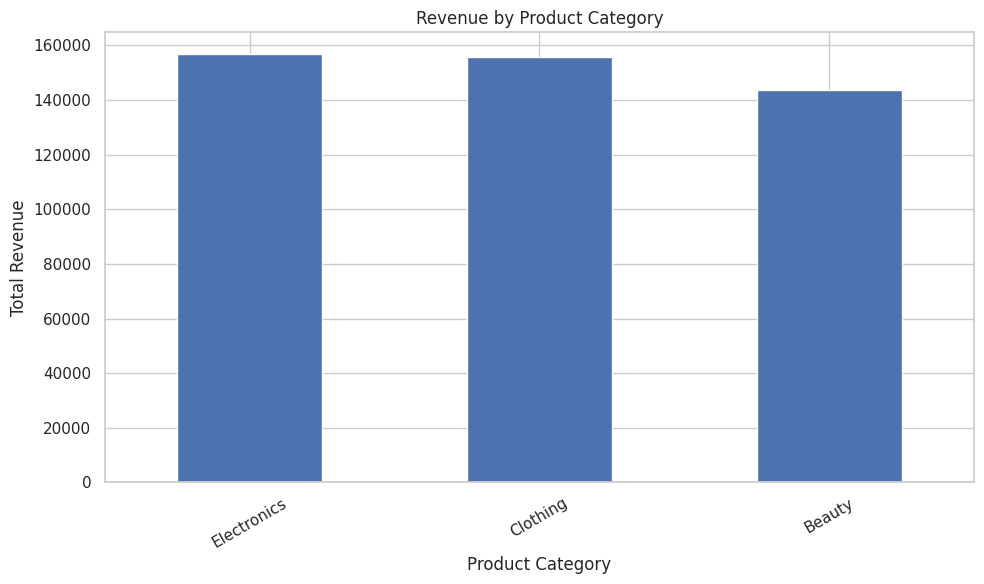

,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [21]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

category_revenue.plot(
    kind="bar",
    rot=30
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.savefig("outputs/category_revenue.png", dpi=300)
plt.show()

display(category_revenue)

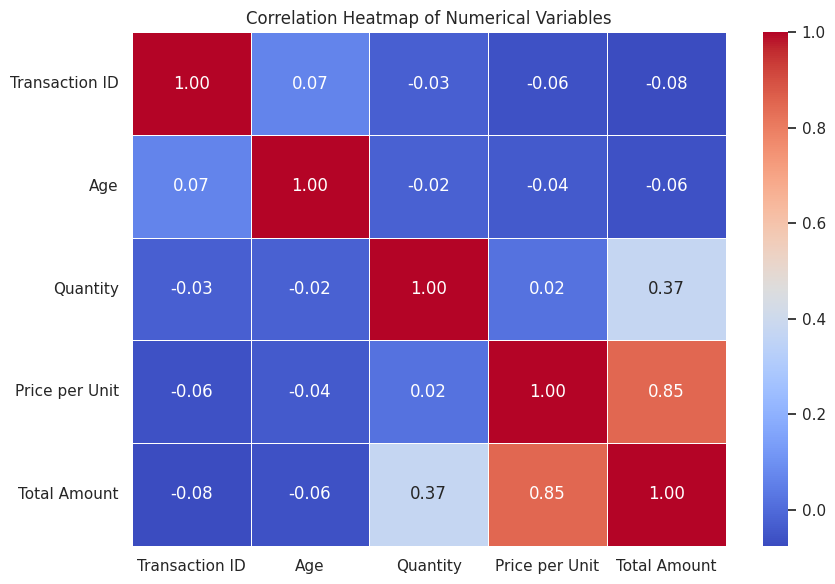

In [22]:
correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()

plt.savefig("outputs/correlation_heatmap.png", dpi=300)
plt.show()

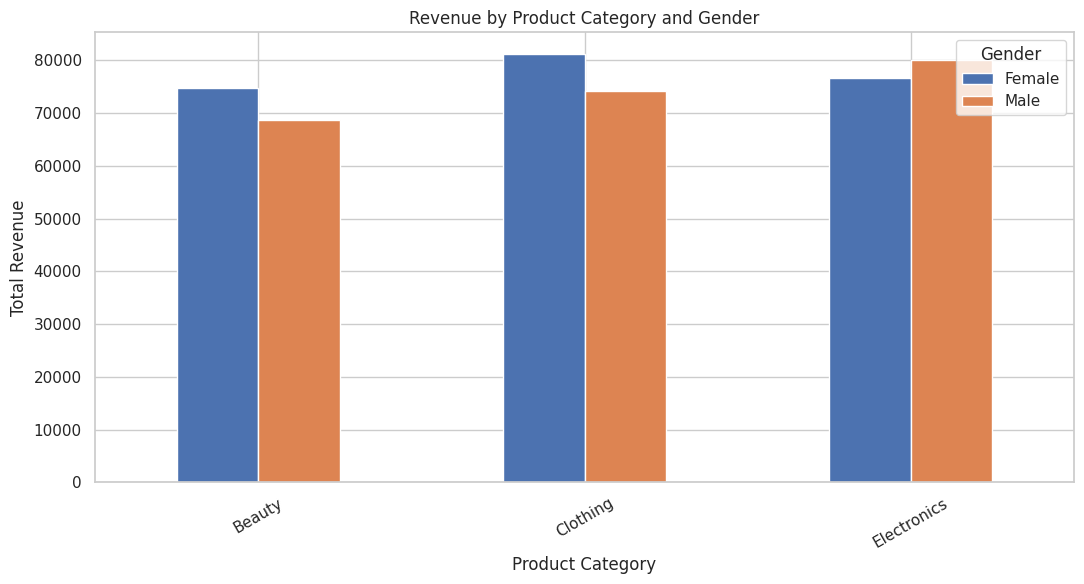

Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


In [23]:
gender_category = df.pivot_table(
    index="Product Category",
    columns="Gender",
    values="Total Amount",
    aggfunc="sum",
    fill_value=0
)

gender_category.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Revenue by Product Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.legend(title="Gender")
plt.tight_layout()

plt.savefig("outputs/revenue_gender_category.png", dpi=300)
plt.show()

display(gender_category)

In [24]:
total_revenue = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
total_quantity = df["Quantity"].sum()
average_transaction = df["Total Amount"].mean()
unique_customers = df["Customer ID"].nunique()

print("RETAIL SALES PERFORMANCE")
print("------------------------")
print(f"Total Revenue: ₦{total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Transaction Value: ₦{average_transaction:,.2f}")
print(f"Unique Customers: {unique_customers:,}")

RETAIL SALES PERFORMANCE
------------------------
Total Revenue: ₦456,000.00
Total Transactions: 1,000
Total Quantity Sold: 2,514
Average Transaction Value: ₦456.00
Unique Customers: 1,000


In [25]:
print("KEY BUSINESS FINDINGS")
print("=====================")

print(
    f"1. Highest-revenue month: {monthly_sales.idxmax()} "
    f"with ₦{monthly_sales.max():,.2f}."
)

print(
    f"2. Lowest-revenue month: {monthly_sales.idxmin()} "
    f"with ₦{monthly_sales.min():,.2f}."
)

print(
    f"3. Highest-revenue product category: "
    f"{category_revenue.idxmax()} "
    f"with ₦{category_revenue.max():,.2f}."
)

print(
    f"4. Highest-quantity category: "
    f"{category_quantity.idxmax()} "
    f"with {category_quantity.max():,.0f} units."
)

print(
    f"5. Largest gender transaction group: "
    f"{gender_counts.idxmax()} "
    f"with {gender_counts.max():,} transactions."
)

print(
    f"6. Largest age group: "
    f"{age_group_counts.idxmax()} "
    f"with {age_group_counts.max():,} transactions."
)

KEY BUSINESS FINDINGS
1. Highest-revenue month: 2023-05 with ₦53,150.00.
2. Lowest-revenue month: 2024-01 with ₦1,530.00.
3. Highest-revenue product category: Electronics with ₦156,905.00.
4. Highest-quantity category: Clothing with 894 units.
5. Largest gender transaction group: Female with 510 transactions.
6. Largest age group: 46-60 with 331 transactions.


## Business Recommendations

Based on the analysis, the following recommendations are proposed:

1. **Sales planning:** The business should study the highest-revenue months and prepare inventory and promotional campaigns ahead of similar periods.

2. **Product strategy:** The business should monitor the highest-revenue product category and maintain sufficient stock while reviewing the performance of lower-revenue categories.

3. **Customer targeting:** Marketing campaigns should consider the age groups and gender segments with the strongest transaction activity, while testing whether targeted campaigns improve sales.

4. **Performance monitoring:** Management should monitor monthly and quarterly revenue to identify declining sales periods early and investigate possible causes.

5. **Further data collection:** The business should collect individual product names and more detailed customer information to support deeper product-level and customer-level analysis.

In [26]:
print("FINAL DATA QUALITY CHECK")
print("========================")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nNumeric summary:")
display(df.describe().round(2))

FINAL DATA QUALITY CHECK
Rows: 1000
Columns: 12
Duplicate rows: 0

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Age Group           0
Month               0
Quarter             0
dtype: int64

Date range:
2023-01-01 00:00:00 to 2024-01-01 00:00:00

Numeric summary:


,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.00,1000,1000.00,1000.00,1000.00,1000.0
mean,500.50,2023-07-03 00:25:55.200000256,41.39,2.51,179.89,456.0
min,1.00,2023-01-01 00:00:00,18.00,1.00,25.00,25.0
25%,250.75,2023-04-08 00:00:00,29.00,1.00,30.00,60.0
50%,500.50,2023-06-29 12:00:00,42.00,3.00,50.00,135.0
75%,750.25,2023-10-04 00:00:00,53.00,4.00,300.00,900.0
max,1000.00,2024-01-01 00:00:00,64.00,4.00,500.00,2000.0
std,288.82,NaN,13.68,1.13,189.68,560.0


In [29]:
df["Calculated Amount"] = (
    df["Quantity"] * df["Price per Unit"]
)

df["Amount Difference"] = (
    df["Total Amount"] - df["Calculated Amount"]
)

print(
    "Transactions where calculated and recorded amounts differ:",
    (df["Amount Difference"].abs() > 0.01).sum()
)

display(
    df.loc[
        df["Amount Difference"].abs() > 0.01,
        ["Transaction ID", "Quantity", "Price per Unit",
         "Total Amount", "Calculated Amount"]
    ].head(10)
)

Transactions where calculated and recorded amounts differ: 0


,Transaction ID,Quantity,Price per Unit,Total Amount,Calculated Amount


In [30]:
# Export cleaned dataset
df.to_csv("outputs/cleaned_retail_sales.csv", index=False)

# Export monthly and quarterly summaries
monthly_sales.to_csv("outputs/monthly_sales_summary.csv")
quarterly_sales.to_csv("outputs/quarterly_sales_summary.csv")

# Export product summaries
category_revenue.to_csv("outputs/category_revenue_summary.csv")
category_quantity.to_csv("outputs/category_quantity_summary.csv")

# Export gender and age summaries
gender_counts.to_csv("outputs/gender_summary.csv")
age_group_counts.to_csv("outputs/age_group_summary.csv")

# Create a ZIP containing all outputs
import shutil

shutil.make_archive(
    "Retail_Sales_EDA_Outputs",
    "zip",
    "outputs"
)

print("All project outputs exported successfully!")

All project outputs exported successfully!


In [31]:
from google.colab import files

files.download("Retail_Sales_EDA_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>